# Predicción de tarifas de taxi en Nueva York con PySpark y MLlib

Evan André Santana Pacheco A01769493

**Dataset:** [New York City Taxi Fare Prediction](https://www.kaggle.com/competitions/new-york-city-taxi-fare-prediction) (Kaggle). Cada fila es un viaje y hay que predecir `fare_amount`, la tarifa en dólares.

Peso de 5.7 gb descomprimido, se trabajó con un zip comprimido para hacer la carga a drive más amable y rápida. En esta libreta se procesan 55.4 millones de filas; la regresión lineal entrena con 43.2 millones y GBT con 4.3 millones de filas para entrenar 2 modelos simples, un modelo lineal y un gradient boosted trees que no son complejos pero lo interesante es el procesamiento de datos.

### Instalar PySpark y comprobar Java

Para correr spark necesitamos java.

In [1]:
import os
import re
import subprocess

!pip install -q "pyspark==4.1.4"


def version_java():
    try:
        texto = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    except FileNotFoundError:
        return 0
    coincidencia = re.search(r'version "(\d+)', texto)
    return int(coincidencia.group(1)) if coincidencia else 0


if version_java() < 17:
    print("Instalando Java 17...")
    !apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = f"{os.environ['JAVA_HOME']}/bin:{os.environ['PATH']}"

print("Versión principal de Java:", version_java())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 4.1.4 which is incompatible.
Versión principal de Java: 21


### Montar Drive

El dataset se ha montado en drive lo subí en zip y por comodidad y temas de almacenamiento lo he mantenido en zip, estan las rutas para importar los datos en crudo, los outputs que son los csv para exportar a tableau y por práctica los modelos resultantes de linear regresion y gbt.
Recalco que **`/content`** es el disco de la máquina de Colab. Es mucho más rápido que Drive, pero se borra al cerrar la sesión, así que Spark lee y procesa ahí.

In [2]:
from google.colab import drive

drive.mount("/content/drive")

# Drive
RAIZ_DRIVE = "/content/drive/MyDrive/IAconcentrada/PySparkTaxi"
DATA_DRIVE = f"{RAIZ_DRIVE}/data"
OUTPUTS_DRIVE = f"{RAIZ_DRIVE}/Outputs"
MODELOS_DRIVE = f"{RAIZ_DRIVE}/modelos"
PARQUET_DRIVE = f"{DATA_DRIVE}/train_parquet"

# En /content: copias de trabajo rápidas
LOCAL = "/content/taxi"
CSV_LOCAL = f"{LOCAL}/csv"
PARQUET_LOCAL = f"{LOCAL}/train_parquet"
FEATURES_LOCAL = f"{LOCAL}/features"
TRAIN_LOCAL = f"{LOCAL}/train_80"
TEST_LOCAL = f"{LOCAL}/test_20"
MODELOS_LOCAL = f"{LOCAL}/modelos"

for carpeta in [OUTPUTS_DRIVE, MODELOS_DRIVE, CSV_LOCAL, MODELOS_LOCAL]:
    os.makedirs(carpeta, exist_ok=True)

if not os.path.isdir(DATA_DRIVE):
    raise FileNotFoundError(f"No encontré la carpeta {DATA_DRIVE}. Revisa la estructura de la sección 1.")

print("Contenido de data:", sorted(os.listdir(DATA_DRIVE)))

Mounted at /content/drive
Contenido de data: ['new-york-city-taxi-fare-prediction.zip']


### Descomprimir el ZIP en `/content`

El ZIP se queda intacto en Drive y solo se descomprime en la máquina de Colab. Spark no puede trabajar ni partir un `.zip` en bloques, pero sí un CSV sin comprimir.

In [3]:
import glob
import shutil
import zipfile

zips = sorted(glob.glob(f"{DATA_DRIVE}/*.zip"))


def buscar_csv(nombre):
    encontrados = glob.glob(f"{CSV_LOCAL}/**/{nombre}", recursive=True)
    return encontrados[0] if encontrados else None


if buscar_csv("train.csv") is None:
    if not zips:
        raise FileNotFoundError(f"No hay ningún .zip en {DATA_DRIVE}. Sube ahí el ZIP de Kaggle.")
    for ruta_zip in zips:
        print("Descomprimiendo", os.path.basename(ruta_zip), "...")
        with zipfile.ZipFile(ruta_zip) as archivo_zip:
            archivo_zip.extractall(CSV_LOCAL)

RUTA_TRAIN_CSV = buscar_csv("train.csv")
RUTA_KAGGLE_CSV = buscar_csv("test.csv")

if RUTA_TRAIN_CSV is None or RUTA_KAGGLE_CSV is None:
    raise FileNotFoundError("El ZIP debe contener train.csv y test.csv.")

for ruta in [RUTA_TRAIN_CSV, RUTA_KAGGLE_CSV]:
    print(f"{os.path.basename(ruta):>10}: {os.path.getsize(ruta) / 1024**3:.2f} GB")

Descomprimiendo new-york-city-taxi-fare-prediction.zip ...
 train.csv: 5.31 GB
  test.csv: 0.00 GB


###  Iniciamos sesión sparksession

La memoria debe definirse **antes** de crear la sesión. Si la cambias después, reinicia el entorno de ejecución para que tome efecto.

* master: local

Simula un clúster con todos los núcleos de esta máquina.
* spark.driver.memory

65% de la RAM, el valor por defecto es de 1 GB; en modo local el driver también hace el trabajo de los executors.

* spark.sql.shuffle.partitions

16 Las 200 que trae por defecto son demasiadas para una sola máquina.


In [4]:
import time
from contextlib import contextmanager
from functools import reduce

import matplotlib.pyplot as plt
import pandas as pd
import pyspark.sql.functions as F
from matplotlib.ticker import FuncFormatter
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import OneHotEncoder, VectorAssembler
from pyspark.ml.regression import GBTRegressor, LinearRegression
from pyspark.sql import SparkSession
from pyspark.sql.types import DoubleType, IntegerType, StringType, StructField, StructType, TimestampType

ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024**3
memoria_driver = f"{max(2, int(ram_gb * 0.65))}g"

spark = (
    SparkSession.builder
    .appName("TaxiFare_PySpark")
    .master("local[*]")
    .config("spark.driver.memory", memoria_driver)
    .config("spark.sql.shuffle.partitions", "16")
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

print("Versión de Spark :", spark.version)
print(f"RAM de la máquina: {ram_gb:.1f} GB  |  Memoria para Spark: {memoria_driver}")
print("Núcleos           :", spark.sparkContext.defaultParallelism)

Versión de Spark : 4.1.4
RAM de la máquina: 12.7 GB  |  Memoria para Spark: 8g
Núcleos           : 2


### funcs de apoyo

* cronometro(etiqueta)

Mide el tiempo de ejecución de un bloque de código e imprime los segundos transcurridos al finalizar.


* tamano_gb(ruta)

Calcula el peso en GB de un archivo o del contenido total de una carpeta.


* copiar_a_drive(origen, destino)

Copia archivos a Google Drive de forma segura mediante un archivo temporal para evitar corrupción por desconexiones.


* exportar_csv(datos, nombre_archivo)

Unifica los datos fragmentados de Spark y los guarda como un único archivo CSV en Google Drive.


In [5]:
@contextmanager
def cronometro(etiqueta):
    inicio = time.perf_counter()
    yield
    print(f"[{etiqueta}] {time.perf_counter() - inicio:,.1f} s")


def tamano_gb(ruta):
    if os.path.isfile(ruta):
        return os.path.getsize(ruta) / 1024**3
    total = sum(os.path.getsize(os.path.join(raiz, archivo)) for raiz, _, archivos in os.walk(ruta) for archivo in archivos)
    return total / 1024**3


def copiar_a_drive(origen, destino):
    temporal = f"{destino}_tmp"
    shutil.rmtree(temporal, ignore_errors=True)
    shutil.copytree(origen, temporal, ignore=shutil.ignore_patterns("*.crc"))
    shutil.rmtree(destino, ignore_errors=True)
    os.rename(temporal, destino)


def exportar_csv(datos, nombre_archivo):
    temporal = f"{LOCAL}/csv_temporal/{nombre_archivo}"
    datos.coalesce(1).write.mode("overwrite").option("header", True).csv(temporal)
    parte = glob.glob(f"{temporal}/part-*.csv")[0]
    destino = f"{OUTPUTS_DRIVE}/{nombre_archivo}"
    shutil.copy(parte, destino)
    print(f"Guardado: {destino}  ({os.path.getsize(destino) / 1024**2:.2f} MB)")
    return destino

### Teoria cluster
Si se implementara el cluster con otras maquinas entonces:

* Cambia la distribución de datos

El dataset no se guarda en una sola máquina; se divide en particiones repartidas en los discos de los workers.

* Procesamiento

En vez de mover datos pesados por la red, Spark envía el código a cada worker para procesar sus particiones asignadas localmente.

* Entrenamiento colaborativo

Durante el entrenamiento, los workers calculan resultados intermedios de sus datos y envían pequeños resúmenes al driver, quien consolida el modelo global.

* Predicción en paralelo

Al predecir, el Driver envía una copia completa del modelo final a cada worker para procesar sus particiones de forma independiente y rápida.

-----------

Aprovecho para mencionar y hacer notas:

* Driver

Este es el cerebro y el que ejecuta la funcion main de la aplicación e inicia sesion. Analiza el codigo, construye el plan, divide las tareas en tasks y cordina la distribudion de estas tareas a los executors, al final se encarga de recopilar los resultados de las acciones ejecutadas.

* Cluster manager

Es el servicio que gestiona y distribuye los recursos físicos de cpu y memoria del cluster en cada máquina, llámese Yarn, Kubernetes, mesos el driver solicita recursos y el manager decidirá en qué máquinas de trabajo se levantarán los executors.
* Executors

Son procesos que se ejecutan en los nodos workers, tienen la tarea de procesar las operaciones en paralelo mediante hilos y almacenar caché o memoria los datos resultantes y devuelven resultados al driver.

* En cuestión del almacenamiento en un cluster distribuido las máquinas no tienen acceso al almacenamiento local de otras por ello es necesario el uso de sistemas de archivos compartidos como hadoop distributed que permiten lecturas simultáneas de nodos.

* Shuffle, en la teoría: no es una operación; es el movimiento de datos entre executors que provocan groupBy o join. Esta transmisión a través de la red es el proceso computacional más costoso y lento en spark, un cuello de botella.

* Si se cae una máquina o nodo se caen en el procesamiento y se pierden particiones de datos de memoria, afortunadamente spark no necesita reiniciar todo el trabajo desde el principio ni recurrir a copias que son costas. El registro de transformaciones es la clave para que se pueda reconstruir y volver a recalcular en paralelo únicamente particiones de datos caídas.


* Para cambiar de local a un clúster real tendríamos que modificar el parámetro .master() para que apunte al gestor del clúster correspondiente, reemplazar las rutas locales por sistemas de almacenamiento compartido distribuido y enviar el script de producción empaquetado utilizando spark-submit en lugar de ejecutarlo interactivamente en un notebook, manteniendo intactas las transformaciones lógicas del código.

## Bloquecitos

Leemos el CSV con esquema explícito; si usáramos `inferSchema=True`, Spark tendría que recorrer los 5.3 GiB solo para adivinar los tipos. Al escribir el esquema explícito, la lectura es inmediata y controlamos el tipo de cada columna.

Las fechas vienen como `2009-06-15 17:26:21 UTC`, por eso se indica ese formato al leer.

In [6]:
FORMATO_FECHA = "yyyy-MM-dd HH:mm:ss 'UTC'"

esquema_kaggle = StructType([
    StructField("key", StringType()),
    StructField("pickup_datetime", TimestampType()),
    StructField("pickup_longitude", DoubleType()),
    StructField("pickup_latitude", DoubleType()),
    StructField("dropoff_longitude", DoubleType()),
    StructField("dropoff_latitude", DoubleType()),
    StructField("passenger_count", IntegerType()),
])

campos_train = esquema_kaggle.fields[:1] + [StructField("fare_amount", DoubleType())] + esquema_kaggle.fields[1:]
esquema_train = StructType(campos_train)

df_csv = spark.read.csv(RUTA_TRAIN_CSV, header=True, schema=esquema_train, timestampFormat=FORMATO_FECHA)
df_csv.printSchema()

root
 |-- key: string (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- pickup_datetime: timestamp (nullable = true)
 |-- pickup_longitude: double (nullable = true)
 |-- pickup_latitude: double (nullable = true)
 |-- dropoff_longitude: double (nullable = true)
 |-- dropoff_latitude: double (nullable = true)
 |-- passenger_count: integer (nullable = true)



Spark parte el archivo en bloques de hasta 128 MB (`spark.sql.files.maxPartitionBytes`). Abajo contamos cuántas filas le tocaron a cada uno con `spark_partition_id()`.
Son 43 particiones y un total aprox 55.4 millones de filas.

In [7]:
num_particiones = df_csv.rdd.getNumPartitions()
tamano_mb = os.path.getsize(RUTA_TRAIN_CSV) / 1024**2

print(f"Tamaño del CSV         : {tamano_mb:,.0f} MB")
print(f"Tamaño / 128 MB        : {tamano_mb / 128:.1f}")
print(f"Particiones que creó Spark: {num_particiones}")

with cronometro("Contar filas por partición en el CSV"):
    filas_por_particion = (
        df_csv.withColumn("particion", F.spark_partition_id())
        .groupBy("particion")
        .count()
        .orderBy("particion")
        .toPandas()
    )

total_filas = int(filas_por_particion["count"].sum())
print(f"Total de filas         : {total_filas:,}")
print(f"Filas por partición    : mínimo {filas_por_particion['count'].min():,}  |  promedio {filas_por_particion['count'].mean():,.0f}  |  máximo {filas_por_particion['count'].max():,}")
filas_por_particion.head(10)

Tamaño del CSV         : 5,433 MB
Tamaño / 128 MB        : 42.4
Particiones que creó Spark: 43
[Contar filas por partición en el CSV] 56.7 s
Total de filas         : 55,423,856
Filas por partición    : mínimo 583,917  |  promedio 1,288,927  |  máximo 1,306,043


,particion,count
0,0,1305512
1,1,1305712
2,2,1305790
3,3,1305522
4,4,1305541
5,5,1305839
6,6,1305714
7,7,1305672
8,8,1305737
9,9,1305800


### Lazy eval
Spark no procesa ningún dato ni ejecuta cálculos cuando se definen las transformaciones  sino que solo registra los pasos en un plan lógico. Los datos reales solo se procesan cuando solicitas explícitamente una acción, lo que permite a Spark optimizar todo el proceso antes de empezar.

In [8]:
with cronometro("Transformaciones: filter + select"):
    consulta_csv = df_csv.filter(F.col("fare_amount") < 0).select("fare_amount", "pickup_datetime")

consulta_csv.explain()

with cronometro("Acción: count()"):
    tarifas_negativas = consulta_csv.count()

print(f"Tarifas negativas: {tarifas_negativas:,}")

[Transformaciones: filter + select] 0.1 s
== Physical Plan ==
*(1) Filter (isnotnull(fare_amount#1) AND (fare_amount#1 < 0.0))
+- FileScan csv [fare_amount#1,pickup_datetime#2] Batched: false, DataFilters: [isnotnull(fare_amount#1), (fare_amount#1 < 0.0)], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/content/taxi/csv/train.csv], PartitionFilters: [], PushedFilters: [IsNotNull(fare_amount), LessThan(fare_amount,0.0)], ReadSchema: struct<fare_amount:double,pickup_datetime:timestamp>


[Acción: count()] 102.3 s
Tarifas negativas: 2,454


Se tarda milésimas de segundo porque todavía no leen nada.

## CSV a Parquet

Parquet guarda los datos por columnas y comprimidos. Si una consulta usa una sola columna, Spark lee solo esa columna, mientras que un CSV debería recorrer cada línea completa de punta a punta. En este paso también quitamos `key`, que es un identificador que no sirve para entrenar y sería la columna más pesada de almacenar.

*Nota sobre almacenamiento:* Google Drive sube los archivos en segundo plano, por lo que una copia previa puede quedar incompleta. Debido a esto, ahora la libreta compara las filas del archivo Parquet con las del CSV original antes de usarlo para asegurar la integridad de los datos. Si necesitas repetir el proceso rápidamente, se puede reutilizar una copia desde Drive.

In [9]:
if os.path.exists(f"{PARQUET_LOCAL}/_SUCCESS"):
    print("El Parquet ya está en /content.")
elif os.path.exists(f"{PARQUET_DRIVE}/_SUCCESS"):
    with cronometro("Copiar Parquet de Drive a /content"):
        shutil.copytree(PARQUET_DRIVE, PARQUET_LOCAL, dirs_exist_ok=True)
else:
    with cronometro("Convertir CSV a Parquet"):
        df_csv.drop("key").write.mode("overwrite").parquet(PARQUET_LOCAL)
    with cronometro("Copiar Parquet a Drive"):
        copiar_a_drive(PARQUET_LOCAL, PARQUET_DRIVE)

df = spark.read.parquet(PARQUET_LOCAL)
filas_parquet = df.count()

if filas_parquet != total_filas:
    print(f"El Parquet tiene {filas_parquet:,} filas y el CSV {total_filas:,}: la copia estaba incompleta y se regenera.")
    shutil.rmtree(PARQUET_LOCAL, ignore_errors=True)
    with cronometro("Convertir CSV a Parquet"):
        df_csv.drop("key").write.mode("overwrite").parquet(PARQUET_LOCAL)
    with cronometro("Copiar Parquet a Drive"):
        copiar_a_drive(PARQUET_LOCAL, PARQUET_DRIVE)
    shutil.rmtree(MODELOS_DRIVE, ignore_errors=True)
    os.makedirs(MODELOS_DRIVE, exist_ok=True)
    print("Se borraron los modelos guardados en Drive para volver a entrenarlos con los datos completos.")
    df = spark.read.parquet(PARQUET_LOCAL)
    filas_parquet = df.count()

df_kaggle = spark.read.csv(RUTA_KAGGLE_CSV, header=True, schema=esquema_kaggle, timestampFormat=FORMATO_FECHA)

print(f"Filas en Parquet       : {filas_parquet:,}  (CSV: {total_filas:,})")
print(f"Filas en test.csv      : {df_kaggle.count():,}")
print(f"Particiones del Parquet: {df.rdd.getNumPartitions()}")
df.show(5)

[Convertir CSV a Parquet] 324.7 s
[Copiar Parquet a Drive] 28.4 s
Filas en Parquet       : 55,423,856  (CSV: 55,423,856)
Filas en test.csv      : 9,914
Particiones del Parquet: 22
+-----------+-------------------+------------------+------------------+------------------+-----------------+---------------+
|fare_amount|    pickup_datetime|  pickup_longitude|   pickup_latitude| dropoff_longitude| dropoff_latitude|passenger_count|
+-----------+-------------------+------------------+------------------+------------------+-----------------+---------------+
|       13.0|2015-06-23 04:22:05|-73.97948455810547|40.761165618896484|-73.95683288574219|40.74489974975586|              1|
|       12.5|2009-10-11 04:05:42|        -73.989029|         40.718912|        -73.986022|        40.762158|              2|
|        4.5|2011-01-22 21:44:00|        -73.977225|         40.743028|        -73.982867|        40.745167|              5|
|        4.9|2011-11-14 22:02:00|        -73.996542|         40.737802


### Revisamos ambos formatos


Haremos un check para ver que  se haya implementado correctamente parquet y comprobaremos el rendimiento y almacenamiento con la misma consulta sobre cada formato y el promedio de una sola columna.


El Parquet también puede tener menos particiones que el CSV: como pesa menos, Spark junta sus archivos en bloques de hasta 128 MB.


In [10]:
inicio = time.perf_counter()
df_csv.agg(F.avg("fare_amount")).collect()
tiempo_csv = time.perf_counter() - inicio

inicio = time.perf_counter()
df.agg(F.avg("fare_amount")).collect()
tiempo_parquet = time.perf_counter() - inicio

display(pd.DataFrame({
    "Formato": ["CSV", "Parquet"],
    "Tamaño (GB)": [round(tamano_gb(RUTA_TRAIN_CSV), 2), round(tamano_gb(PARQUET_LOCAL), 2)],
    "Promedio de una columna (s)": [round(tiempo_csv, 1), round(tiempo_parquet, 1)],
}))

df.filter(F.col("fare_amount") < 0).select("fare_amount").explain()

,Formato,Tamaño (GB),Promedio de una columna (s)
0,CSV,5.31,101.1
1,Parquet,2.08,2.1


== Physical Plan ==
*(1) Filter (isnotnull(fare_amount#45) AND (fare_amount#45 < 0.0))
+- *(1) ColumnarToRow
   +- FileScan parquet [fare_amount#45] Batched: true, DataFilters: [isnotnull(fare_amount#45), (fare_amount#45 < 0.0)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/content/taxi/train_parquet], PartitionFilters: [], PushedFilters: [IsNotNull(fare_amount), LessThan(fare_amount,0.0)], ReadSchema: struct<fare_amount:double>




## Mini EDA

 Solo pasan a pandas tablas ya resumidas, de unas cuantas filas.


Revisamos las estadísticas básicas, máximos, mínimos, promedios, también los nulos y los percentiles.



In [11]:
with cronometro("describe()"):
    df.describe().show(truncate=12)

with cronometro("Nulos por columna"):
    df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns]).show(vertical=True)

percentiles = [0.001, 0.01, 0.5, 0.99, 0.999]
with cronometro("Percentiles aproximados"):
    valores = df.approxQuantile(["fare_amount", "passenger_count"], percentiles, 0.001)

display(pd.DataFrame(valores, index=["fare_amount", "passenger_count"], columns=[f"p{p * 100:g}" for p in percentiles]))

+-------+------------+----------------+---------------+-----------------+----------------+---------------+
|summary| fare_amount|pickup_longitude|pickup_latitude|dropoff_longitude|dropoff_latitude|passenger_count|
+-------+------------+----------------+---------------+-----------------+----------------+---------------+
|  count|    55423856|        55423856|       55423856|         55423480|        55423480|       55423856|
|   mean|11.345045...|    -72.50968...|   39.919791...|     -72.51120...|    39.920681...|   1.6853799...|
| stddev|20.710832...|    12.848883...|   9.6423530...|     12.782196...|    9.6333457...|   1.3276643...|
|    min|      -300.0|    -3442.059565|   -3492.263768|     -3442.024565|    -3547.886698|              0|
|    max|    93963.36|     3457.625683|    3408.789565|       3457.62235|     3537.132528|            208|
+-------+------------+----------------+---------------+-----------------+----------------+---------------+

[describe()] 22.9 s
-RECORD 0-------

,p0.1,p1,p50,p99,p99.9
fare_amount,-300.0,3.3,8.5,53.0,93963.36
passenger_count,0.0,1.0,1.0,6.0,208.00


### Graphs


In [12]:
COLOR_SERIE = "#2a78d6"
COLOR_TEXTO = "#0b0b0b"
COLOR_TEXTO_2 = "#52514e"
COLOR_REJILLA = "#e4e3df"
COLOR_FONDO = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": COLOR_FONDO,
    "axes.facecolor": COLOR_FONDO,
    "axes.edgecolor": COLOR_REJILLA,
    "axes.titlecolor": COLOR_TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": COLOR_TEXTO_2,
    "xtick.color": COLOR_TEXTO_2,
    "ytick.color": COLOR_TEXTO_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": COLOR_REJILLA,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})


def formato_numero(valor, _=None):
    if abs(valor) >= 1e6:
        return f"{valor / 1e6:.1f} M"
    if abs(valor) >= 1e4:
        return f"{valor / 1e3:.0f} mil"
    return f"{valor:,.0f}"


def formato_dolares(valor, _=None):
    return f"${valor:,.0f}"


def columnas(eje, etiquetas, valores, titulo, formato=formato_numero, etiqueta_x=None, cada=1):
    posiciones = list(range(len(valores)))
    eje.bar(posiciones, valores, width=0.72, color=COLOR_SERIE)
    eje.set_title(titulo)
    eje.yaxis.set_major_formatter(FuncFormatter(formato))
    eje.set_xticks(posiciones[::cada], [str(e) for e in etiquetas][::cada])
    eje.tick_params(axis="both", length=0)
    if etiqueta_x:
        eje.set_xlabel(etiqueta_x)

[Agregar por año y hora] 23.4 s
[Histograma de tarifas] 7.9 s


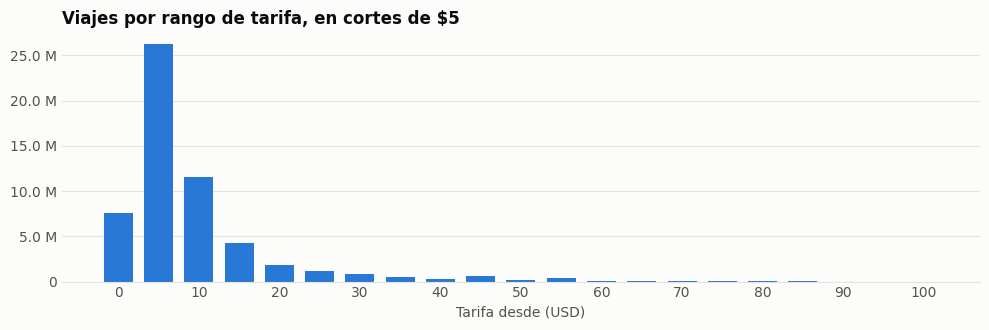

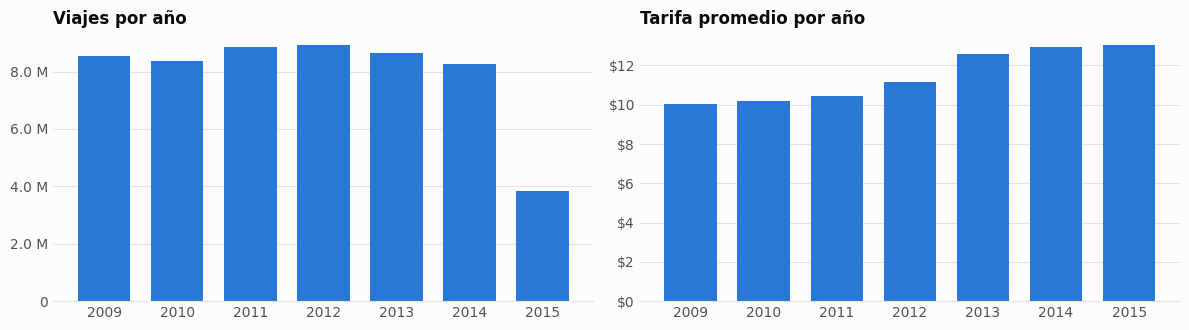

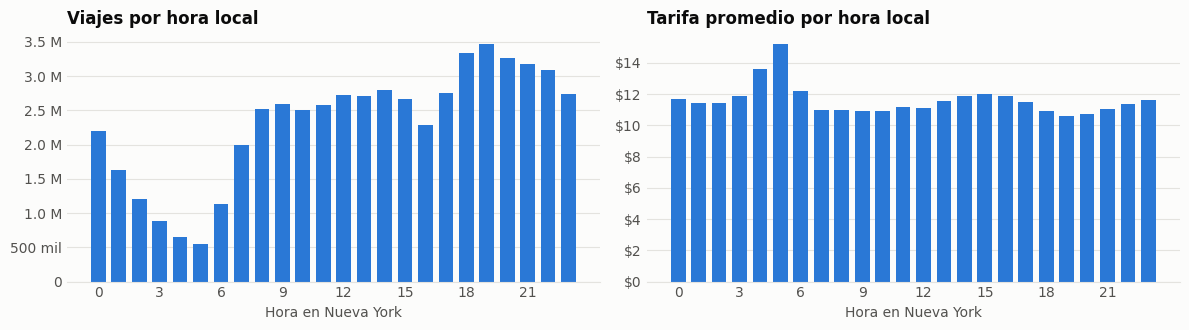

,anio,viajes,tarifa_promedio
0,2009,8543166,10.06
1,2010,8353745,10.17
2,2011,8841346,10.45
3,2012,8919666,11.18
4,2013,8654850,12.60
5,2014,8252671,12.92
6,2015,3854578,13.03


In [13]:
fecha_local = F.col("pickup_datetime")

with cronometro("Agregar por año y hora"):
    resumen = (
        df.filter((F.col("fare_amount") > 0) & F.col("pickup_datetime").isNotNull())
        .withColumn("anio", F.year(fecha_local))
        .withColumn("hora", F.hour(fecha_local))
        .groupBy("anio", "hora")
        .agg(F.count("*").alias("viajes"), F.sum("fare_amount").alias("suma_tarifa"))
        .toPandas()
    )

with cronometro("Histograma de tarifas"):
    histograma = (
        df.filter(F.col("fare_amount").between(0, 100))
        .withColumn("desde", F.floor(F.col("fare_amount") / 5) * 5)
        .groupBy("desde")
        .count()
        .orderBy("desde")
        .toPandas()
    )

por_anio = resumen.groupby("anio", as_index=False)[["viajes", "suma_tarifa"]].sum().sort_values("anio")
por_hora = resumen.groupby("hora", as_index=False)[["viajes", "suma_tarifa"]].sum().sort_values("hora")
por_anio["tarifa_promedio"] = por_anio["suma_tarifa"] / por_anio["viajes"]
por_hora["tarifa_promedio"] = por_hora["suma_tarifa"] / por_hora["viajes"]

fig, eje = plt.subplots(figsize=(10, 3.4))
columnas(eje, histograma["desde"].astype(int), histograma["count"], "Viajes por rango de tarifa, en cortes de $5", etiqueta_x="Tarifa desde (USD)", cada=2)
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4))
columnas(ejes[0], por_anio["anio"], por_anio["viajes"], "Viajes por año")
columnas(ejes[1], por_anio["anio"], por_anio["tarifa_promedio"], "Tarifa promedio por año", formato=formato_dolares)
plt.tight_layout()
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4))
columnas(ejes[0], por_hora["hora"], por_hora["viajes"], "Viajes por hora local", etiqueta_x="Hora en Nueva York", cada=3)
columnas(ejes[1], por_hora["hora"], por_hora["tarifa_promedio"], "Tarifa promedio por hora local", formato=formato_dolares, etiqueta_x="Hora en Nueva York", cada=3)
plt.tight_layout()
plt.show()

display(por_anio[["anio", "viajes", "tarifa_promedio"]].round(2))

### Observaciones:

* Casi la mitad de los viajes se concentra en el rango de 5 a 10 USD.
* La tarifa promedio por año sube constantemente con los años. El incremento más notable ocurre en 2013, donde la tarifa promedio saltó de aprox 11 USD (en 2012) a aprox 12.50 USD. Este salto coincide históricamente con el aumento de tarifas de cerca del 17% que aprobó la TLC (Taxi and Limousine Commission) en septiembre de 2012.
* El volumen de viajes alcanza su pico por la tarde-noche a las 19:00 horas y registra su mínimo a las 05:00 horas de la mañana.
* Curiosamente, la tarifa promedio más alta se registra precisamente a las 05:00 horas, alcanzando un valor de aproximadamente 15 USD, seguida por un pico a las 04:00 horas con unos $13.60.

## Limpieza

No tomaremos en cuenta valores nulos, las tarifas serán consideradas únicamente de $2.50 a $250 USD, las coordenadas dentro del rango de longitud de −74.5 a −72.8 y latitud de 40.5 a 41.8, y el número de pasajeros de 1 a 6. Todos estos conteos se calculan en una sola agregación en Spark para no recorrer los datos múltiples veces.


In [14]:
TARIFA_MIN, TARIFA_MAX = 2.5, 250.0
LON_MIN, LON_MAX = -74.5, -72.8
LAT_MIN, LAT_MAX = 40.5, 41.8
PASAJEROS_MIN, PASAJEROS_MAX = 1, 6

tarifa_ok = F.col("fare_amount").between(TARIFA_MIN, TARIFA_MAX)
coordenadas_ok = (
    F.col("pickup_longitude").between(LON_MIN, LON_MAX)
    & F.col("dropoff_longitude").between(LON_MIN, LON_MAX)
    & F.col("pickup_latitude").between(LAT_MIN, LAT_MAX)
    & F.col("dropoff_latitude").between(LAT_MIN, LAT_MAX)
)
pasajeros_ok = F.col("passenger_count").between(PASAJEROS_MIN, PASAJEROS_MAX)
sin_nulos = reduce(lambda a, b: a & b, [F.col(c).isNotNull() for c in df.columns])
fila_valida = sin_nulos & tarifa_ok & coordenadas_ok & pasajeros_ok

rangos_kaggle = df_kaggle.agg(
    F.min("pickup_longitude").alias("lon_min_origen"), F.max("pickup_longitude").alias("lon_max_origen"),
    F.min("dropoff_longitude").alias("lon_min_destino"), F.max("dropoff_longitude").alias("lon_max_destino"),
    F.min("pickup_latitude").alias("lat_min_origen"), F.max("pickup_latitude").alias("lat_max_origen"),
    F.min("dropoff_latitude").alias("lat_min_destino"), F.max("dropoff_latitude").alias("lat_max_destino"),
    F.min("passenger_count").alias("pasajeros_min"), F.max("passenger_count").alias("pasajeros_max"),
)
rangos_kaggle.show(vertical=True)

with cronometro("Contar filas por regla (una sola pasada)"):
    conteos = df.agg(
        F.count("*").alias("total"),
        F.count(F.when(~sin_nulos, 1)).alias("nulos"),
        F.count(F.when(~tarifa_ok, 1)).alias("tarifa"),
        F.count(F.when(~coordenadas_ok, 1)).alias("coordenadas"),
        F.count(F.when(~pasajeros_ok, 1)).alias("pasajeros"),
        F.count(F.when(fila_valida, 1)).alias("validas"),
    ).first()

total = conteos["total"]
validas = conteos["validas"]

display(pd.DataFrame({
    "Motivo": ["Algún valor nulo", "Tarifa fuera de rango", "Coordenadas fuera de la zona", "Pasajeros fuera de rango", "TOTAL eliminadas"],
    "Filas": [conteos["nulos"], conteos["tarifa"], conteos["coordenadas"], conteos["pasajeros"], total - validas],
    "% del total": [round(n / total * 100, 3) for n in [conteos["nulos"], conteos["tarifa"], conteos["coordenadas"], conteos["pasajeros"], total - validas]],
}))
print(f"Filas originales: {total:,}  |  Filas válidas: {validas:,}  ({validas / total * 100:.2f}%)")
print("Una fila puede romper varias reglas, por eso la suma de los motivos puede ser mayor que el total eliminado.")

df_limpio = df.filter(fila_valida)

-RECORD 0---------------------
 lon_min_origen  | -74.252193 
 lon_max_origen  | -72.986532 
 lon_min_destino | -74.263242 
 lon_max_destino | -72.990963 
 lat_min_origen  | 40.573143  
 lat_max_origen  | 41.709555  
 lat_min_destino | 40.568973  
 lat_max_destino | 41.696683  
 pasajeros_min   | 1          
 pasajeros_max   | 6          

[Contar filas por regla (una sola pasada)] 23.8 s


,Motivo,Filas,% del total
0,Algún valor nulo,376,0.001
1,Tarifa fuera de rango,5453,0.010
2,Coordenadas fuera de la zona,1174483,2.119
3,Pasajeros fuera de rango,195532,0.353
4,TOTAL eliminadas,1370148,2.472


Filas originales: 55,423,856  |  Filas válidas: 54,053,708  (97.53%)
Una fila puede romper varias reglas, por eso la suma de los motivos puede ser mayor que el total eliminado.


## Variables (*features*)

- **Variables de Tiempo:** Extraemos el año, mes, día de la semana y hora.
- **Distancia Haversine:** Calculamos la distancia en línea recta sobre la superficie terrestre (en km) entre origen y destino.
- **Rangos de Distancia:** Agrupamos los trayectos en categorías ordenadas para facilitar el análisis en Tableau.

*Nota de optimización:* Usamos funciones nativas de Spark (`F.sin`, `F.cos`) en vez de funciones personalizadas de Python para evitar transferir millones de filas entre Java y Python, reduciendo drásticamente los tiempos de procesamiento. Finalmente, congelamos los resultados guardándolos en formato Parquet local (`FEATURES_LOCAL`) para evitar re-calcular todo en las fases de entrenamiento.

In [15]:
RADIO_TIERRA_KM = 6371.0


def distancia_haversine(lat1, lon1, lat2, lon2):
    dlat = F.radians(F.col(lat2) - F.col(lat1))
    dlon = F.radians(F.col(lon2) - F.col(lon1))
    a = (
        F.sin(dlat / 2) ** 2
        + F.cos(F.radians(F.col(lat1))) * F.cos(F.radians(F.col(lat2))) * F.sin(dlon / 2) ** 2
    )
    return 2 * RADIO_TIERRA_KM * F.asin(F.sqrt(a))


def agregar_features(datos):
    fecha_local = F.col("pickup_datetime")
    con_distancia = datos.withColumn(
        "distancia_km",
        distancia_haversine("pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"),
    )
    return con_distancia.withColumns({
        "anio": F.year(fecha_local),
        "mes": F.month(fecha_local),
        "dia_semana": F.dayofweek(fecha_local) - 1,
        "hora": F.hour(fecha_local),
        "rango_distancia": (
            F.when(F.col("distancia_km") < 2, "1. 0-2 km")
            .when(F.col("distancia_km") < 5, "2. 2-5 km")
            .when(F.col("distancia_km") < 10, "3. 5-10 km")
            .when(F.col("distancia_km") < 20, "4. 10-20 km")
            .otherwise("5. 20+ km")
        ),
    })


with cronometro("Limpiar, crear variables y guardar en Parquet"):
    agregar_features(df_limpio).write.mode("overwrite").parquet(FEATURES_LOCAL)

df_features = spark.read.parquet(FEATURES_LOCAL)
df_features.select("fare_amount", "distancia_km", "anio", "mes", "dia_semana", "hora", "rango_distancia").show(5)

with cronometro("Revisar la distancia"):
    revision = df_features.agg(
        F.count("*").alias("filas"),
        F.count(F.when(F.col("distancia_km") == 0, 1)).alias("distancia_cero"),
        F.corr("distancia_km", "fare_amount").alias("correlacion_con_tarifa"),
        F.max("distancia_km").alias("distancia_maxima_km"),
    ).first()

print(f"Filas                     : {revision['filas']:,}")
print(f"Viajes con distancia cero : {revision['distancia_cero']:,}")
print(f"Correlación distancia-tarifa: {revision['correlacion_con_tarifa']:.3f}")
print(f"Distancia máxima          : {revision['distancia_maxima_km']:.1f} km")

[Limpiar, crear variables y guardar en Parquet] 180.4 s
+-----------+------------------+----+---+----------+----+---------------+
|fare_amount|      distancia_km|anio|mes|dia_semana|hora|rango_distancia|
+-----------+------------------+----+---+----------+----+---------------+
|       16.1|1.4486781914564841|2010|  9|         1|  20|      1. 0-2 km|
|        7.7|  2.35963027822077|2010| 12|         3|  12|      2. 2-5 km|
|        5.5|0.5227389722493935|2015|  4|         3|  14|      1. 0-2 km|
|       10.5|3.4534526652587303|2010|  1|         6|   2|      2. 2-5 km|
|       10.1|3.5474172326765214|2010|  3|         3|  22|      2. 2-5 km|
+-----------+------------------+----+---+----------+----+---------------+
only showing top 5 rows
[Revisar la distancia] 4.2 s
Filas                     : 54,053,708
Viajes con distancia cero : 573,094
Correlación distancia-tarifa: 0.826
Distancia máxima          : 143.8 km


## División clásico 80/20

Se usará la clásica división 80 train 20 test ya que es más que suficiente. Las ventajas de k fold es el rotar pocos datos para asegurarnos que tenga el mejor desempeño posible con la menor cantidad de datos y se entrena el modelo k veces. Precisamente sobran los datos para tener un entrenamiento robusto, para hacer una prueba y hacer k fold significa entrenar más veces el modelo.,

In [16]:
train_df, test_df = df_features.randomSplit([0.8, 0.2], seed=42)

with cronometro("Dividir y guardar 80/20"):
    train_df.write.mode("overwrite").parquet(TRAIN_LOCAL)
    test_df.write.mode("overwrite").parquet(TEST_LOCAL)

train_df = spark.read.parquet(TRAIN_LOCAL)
test_df = spark.read.parquet(TEST_LOCAL)

print(f"Entrenamiento: {train_df.count():,} filas")
print(f"Prueba       : {test_df.count():,} filas")

[Dividir y guardar 80/20] 424.6 s
Entrenamiento: 43,238,817 filas
Prueba       : 10,814,891 filas


## Modelos con MLlib

Abordamos este problema de **regresión** (predicción de tarifas en dólares) entrenando dos modelos básicos bajo un flujo de `Pipeline`, comparándolos contra una referencia básica:

- **Referencia (Promedio):** Línea base simple que siempre predice el promedio de las tarifas de entrenamiento.
- **Regresión Lineal (`LinearRegression`):** Entrenado con el **80% de entrenamiento**. Es rápido y eficiente. Usa variables temporales (`hora`, `dia_semana`) codificadas con `OneHotEncoder` debido a que son categorías y no variables cuantitativas (las 23 h no valen 23 veces la 1 h).
- **Gradient Boosted Trees (`GBTRegressor`):** Entrenado con una **muestra del 10%** debido a su alto costo computacional. Captura interacciones no lineales complejas directamente sobre variables continuas como las coordenadas geográficas crudas.

*Nota de optimización:* Cada modelo se almacena automáticamente en Google Drive para cargarse directamente en futuras ejecuciones.

### Promedio

In [17]:
ETIQUETA = "fare_amount"
REENTRENAR = False

FRACCION_GBT = 0.10
ARBOLES_GBT = 20
PROFUNDIDAD_GBT = 5


def entrenar_o_cargar(pipeline, datos, nombre):
    ruta_drive = f"{MODELOS_DRIVE}/{nombre}"
    if os.path.exists(f"{ruta_drive}/metadata") and not REENTRENAR:
        print(f"Cargando {nombre} desde Drive; no se vuelve a entrenar.")
        return PipelineModel.load(ruta_drive)
    with cronometro(f"Entrenar {nombre}"):
        modelo = pipeline.fit(datos)
    ruta_local = f"{MODELOS_LOCAL}/{nombre}"
    modelo.write().overwrite().save(ruta_local)
    copiar_a_drive(ruta_local, ruta_drive)
    return modelo

tarifa_promedio_train = train_df.agg(F.avg(ETIQUETA)).first()[0]
print(f"Tarifa promedio en entrenamiento: ${tarifa_promedio_train:.2f}")

Tarifa promedio en entrenamiento: $11.32


###  Regresión lineal

In [18]:
codificador = OneHotEncoder(inputCols=["hora", "dia_semana"], outputCols=["hora_vec", "dia_semana_vec"])
ensamblador_lr = VectorAssembler(
    inputCols=["distancia_km", "anio", "mes", "passenger_count", "hora_vec", "dia_semana_vec"],
    outputCol="features",
)
regresion_lineal = LinearRegression(featuresCol="features", labelCol=ETIQUETA, solver="normal")

pipeline_lr = Pipeline(stages=[codificador, ensamblador_lr, regresion_lineal])

modelo_lr = entrenar_o_cargar(pipeline_lr, train_df, "lr_taxi")

[Entrenar lr_taxi] 325.4 s


### Gradient Boosted Trees

Entrenar todos los árboles con el 80% completo no es práctico en Colab gratis, así que el GBT usa una muestra. Eso le da una desventaja frente a la regresión lineal, pero ambos se comparan con el mismo conjunto de prueba.

Aquí sí conviene `cache()`: la muestra ya es pequeña y el algoritmo la recorre muchas veces.

In [19]:
VARIABLES_GBT = [
    "distancia_km", "anio", "mes", "dia_semana", "hora", "passenger_count",
    "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude",
]

muestra_gbt = train_df.select([ETIQUETA] + VARIABLES_GBT).sample(fraction=FRACCION_GBT, seed=42).cache()
filas_gbt = muestra_gbt.count()
print(f"Muestra para GBT: {filas_gbt:,} filas")

ensamblador_gbt = VectorAssembler(inputCols=VARIABLES_GBT, outputCol="features")
gbt = GBTRegressor(
    featuresCol="features",
    labelCol=ETIQUETA,
    maxIter=ARBOLES_GBT,
    maxDepth=PROFUNDIDAD_GBT,
    stepSize=0.2,
    seed=42,
)
pipeline_gbt = Pipeline(stages=[ensamblador_gbt, gbt])

modelo_gbt = entrenar_o_cargar(pipeline_gbt, muestra_gbt, "gbt_taxi")

muestra_gbt.unpersist()
print("Muestra liberada de la memoria.")

Muestra para GBT: 4,324,267 filas
[Entrenar gbt_taxi] 322.4 s
Muestra liberada de la memoria.


## Evaluación con las herramientas de PySpark

Utilizamos `RegressionEvaluator` de MLlib para medir la precisión de las predicciones en nuestro problema de regresión mediante tres métricas clave:

- **RMSE (Raíz del Error Cuadrático Medio):** Indica el error típico en dólares, aplicando una penalización mayor a las desviaciones grandes.
- **MAE (Error Absoluto Medio):** Representa la desviación promedio absoluta en dólares de las predicciones frente a la tarifa real.
- **R² (Coeficiente de Determinación):** Proporción de la variabilidad de las tarifas explicada por el modelo (una predicción basada en el simple promedio daría un valor cercano a 0).

### Comparación general

In [20]:
def evaluar(predicciones, nombre):
    solo_columnas = predicciones.select(ETIQUETA, "prediction").cache()
    resultado = {"Modelo": nombre, "Filas": solo_columnas.count()}
    for metrica in ["rmse", "mae", "r2"]:
        evaluador = RegressionEvaluator(labelCol=ETIQUETA, predictionCol="prediction", metricName=metrica)
        resultado[metrica.upper()] = round(evaluador.evaluate(solo_columnas), 4) + 0.0
    solo_columnas.unpersist()
    return resultado


predicciones_base = test_df.select(ETIQUETA).withColumn("prediction", F.lit(tarifa_promedio_train))
predicciones_lr = modelo_lr.transform(test_df)
predicciones_gbt = modelo_gbt.transform(test_df)

with cronometro("Evaluar los tres modelos"):
    resultados = pd.DataFrame([
        evaluar(predicciones_base, "Referencia: promedio"),
        evaluar(predicciones_lr, "LinearRegression (80% completo)"),
        evaluar(predicciones_gbt, f"GBTRegressor (muestra de {FRACCION_GBT:.0%})"),
    ])

display(resultados)

[Evaluar los tres modelos] 118.9 s


,Modelo,Filas,RMSE,MAE,R2
0,Referencia: promedio,10814891,9.6334,5.9991,0.0000
1,LinearRegression (80% completo),10814891,5.3277,2.3899,0.6941
2,GBTRegressor (muestra de 10%),10814891,4.1187,1.9818,0.8172


### Error por rango de distancia

Una sola métrica global puede esconder en qué viajes falla el modelo.

In [21]:
def error_por_rango(predicciones, prefijo):
    return (
        predicciones.withColumn("error", F.col("prediction") - F.col(ETIQUETA))
        .groupBy("rango_distancia")
        .agg(
            F.count("*").alias("Viajes"),
            F.avg(ETIQUETA).alias("Tarifa promedio"),
            F.sqrt(F.avg(F.col("error") ** 2)).alias(f"RMSE {prefijo}"),
            F.avg(F.abs(F.col("error"))).alias(f"MAE {prefijo}"),
        )
        .toPandas()
    )


with cronometro("Error por rango"):
    rangos_lr = error_por_rango(predicciones_lr, "LR")
    rangos_gbt = error_por_rango(predicciones_gbt, "GBT").drop(columns=["Viajes", "Tarifa promedio"])

display(rangos_lr.merge(rangos_gbt, on="rango_distancia").sort_values("rango_distancia").round(2))

[Error por rango] 58.0 s


,rango_distancia,Viajes,Tarifa promedio,RMSE LR,MAE LR,RMSE GBT,MAE GBT
4,1. 0-2 km,5017363,6.57,4.67,1.88,4.01,1.57
0,2. 2-5 km,3900998,10.62,3.15,1.92,2.94,1.73
1,3. 5-10 km,1351560,19.48,5.47,3.65,4.50,2.93
3,4. 10-20 km,414676,35.97,10.14,6.86,7.82,5.17
2,5. 20+ km,130294,52.87,24.11,8.67,11.22,5.19


### La importancia de las features

Intercepto: -1,077.29


,Variable,Coeficiente
0,distancia_km,2.1153
1,anio,0.5370
2,mes,0.0753
3,passenger_count,0.0424


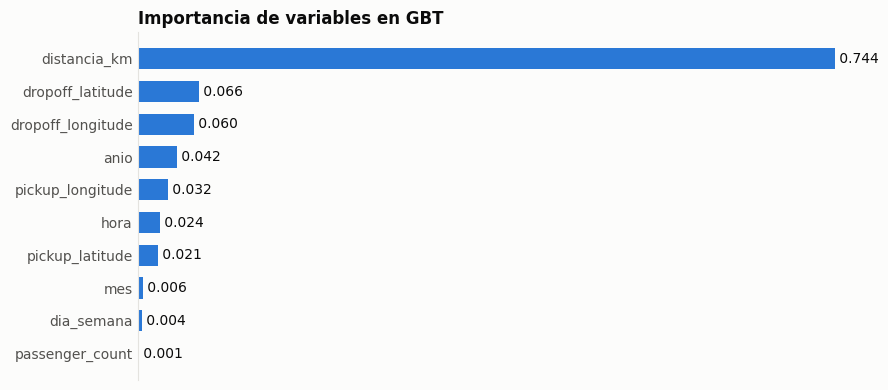

In [22]:

atributos = predicciones_lr.schema["features"].metadata["ml_attr"]["attrs"]
indice_a_nombre = {a["idx"]: a["name"] for grupo in atributos.values() for a in grupo}
modelo_lineal = modelo_lr.stages[-1]

coeficientes = pd.DataFrame({
    "Variable": [indice_a_nombre[i] for i in range(len(modelo_lineal.coefficients))],
    "Coeficiente": modelo_lineal.coefficients.toArray(),
})
print(f"Intercepto: {modelo_lineal.intercept:,.2f}")
display(coeficientes[coeficientes["Variable"].isin(["distancia_km", "anio", "mes", "passenger_count"])].round(4))

importancias = pd.DataFrame({
    "Variable": VARIABLES_GBT,
    "Importancia": modelo_gbt.stages[-1].featureImportances.toArray(),
}).sort_values("Importancia")

fig, eje = plt.subplots(figsize=(9, 4))
eje.barh(importancias["Variable"], importancias["Importancia"], height=0.65, color=COLOR_SERIE)
eje.set_title("Importancia de variables en GBT")
eje.grid(False)
eje.spines["left"].set_visible(True)
eje.tick_params(axis="both", length=0)
eje.set_xticks([])
eje.spines["bottom"].set_visible(False)
for posicion, valor in enumerate(importancias["Importancia"]):
    eje.text(valor, posicion, f" {valor:.3f}", va="center", color=COLOR_TEXTO)
plt.tight_layout()
plt.show()

###  Prueba extra

Simulamos el uso real, entrenamos solo hasta 2014 y medimos con viajes de 2015.

Las dos filas de abajo se evalúan con los mismos viajes de 2015, tomados del 20% de prueba. Si la segunda es mucho peor, el modelo depende de haber visto ese periodo.

In [23]:
train_hasta_2014 = train_df.filter(F.col("anio") <= 2014)
prueba_2015 = test_df.filter(F.col("anio") == 2015)

with cronometro("Prueba temporal"):
    modelo_lr_2014 = pipeline_lr.fit(train_hasta_2014)
    resultados_tiempo = pd.DataFrame([
        evaluar(modelo_lr.transform(prueba_2015), "LR que sí vio viajes de 2015"),
        evaluar(modelo_lr_2014.transform(prueba_2015), "LR entrenada hasta 2014"),
    ])

display(resultados_tiempo)

[Prueba temporal] 256.5 s


,Modelo,Filas,RMSE,MAE,R2
0,LR que sí vio viajes de 2015,756128,5.2582,2.8862,0.7824
1,LR entrenada hasta 2014,756128,5.3272,2.9603,0.7767


En la evaluación de modelos de predicción, la Regresión Lineal y el modelo Gradient Boosted Trees (GBT) mejoran significativamente el promedio simple, cuyo error típico (RMSE) es de 9.63. La Regresión Lineal reduce este error a 5.33 con un R² de 0.69 utilizando el 80% de los datos, mientras que GBT lo disminuye a 4.12 con un R² de 0.82 utilizando únicamente el 10% de los datos, demostrando su capacidad superior para capturar relaciones no lineales complejas sin transformaciones manuales.
Respecto a los errores por rango de distancia, en viajes largos de más de 20 km el error absoluto es mayor (RMSE de 11.22 para GBT), aunque resulta menor en términos relativos en comparación con la tarifa promedio de 53. En cambio, en trayectos cortos de 0 a 2 km, un RMSE de 4.01 representa un margen de error elevado respecto a la tarifa promedio de 6.57.
En cuanto al impacto temporal, el modelo mantiene su robustez al evaluar datos de 2015 no vistos previamente, registrando un RMSE de 5.33 cuando se entrena solo hasta 2014 frente a un RMSE de 5.26 al incluir el año 2015, lo que equivale a una degradación de cerca de 1.3%.
Finalmente, la variable más determinante es la distancia en kilómetros, con una importancia de 0.74 en GBT, seguida por las coordenadas geográficas de origen y destino, las cuales capturan zonas de alta demanda, tráfico y tarifas fijas especiales.



## Guardamos el modelo y predecimos

Elegimos el de menor RMSE y lo cargamos desde Drive. Si el modelo se guardó bien, debe dar exactamente el mismo resultado.

In [24]:
rmse_lr = resultados.loc[1, "RMSE"]
rmse_gbt = resultados.loc[2, "RMSE"]
mejor_nombre = "gbt_taxi" if rmse_gbt < rmse_lr else "lr_taxi"
rmse_esperado = min(rmse_lr, rmse_gbt)

mejor_modelo = PipelineModel.load(f"{MODELOS_DRIVE}/{mejor_nombre}")

rmse_cargado = RegressionEvaluator(labelCol=ETIQUETA, predictionCol="prediction", metricName="rmse").evaluate(
    mejor_modelo.transform(test_df)
)
print(f"Mejor modelo: {mejor_nombre}")
print(f"RMSE del modelo cargado: {rmse_cargado:.4f}  (debe coincidir con {rmse_esperado:.4f})")

Mejor modelo: gbt_taxi
RMSE del modelo cargado: 4.1187  (debe coincidir con 4.1187)


### Predecimos `test.csv` de Kaggle

Los datos de kaggle tiene viajes que el modelo nunca vio y que no traen tarifa. Aplicamos la misma función de variables y el modelo hace el resto. El resultado queda en `Outputs/predicciones_test.csv`.

In [25]:
predicciones_kaggle = mejor_modelo.transform(agregar_features(df_kaggle)).select(
    "key",
    F.round("prediction", 2).alias("fare_amount"),
)

predicciones_kaggle.show(5, truncate=False)
predicciones_kaggle.describe("fare_amount").show()
ruta_predicciones = exportar_csv(predicciones_kaggle, "predicciones_test.csv")

+---------------------------+-----------+
|key                        |fare_amount|
+---------------------------+-----------+
|2015-01-27 13:08:24.0000002|11.06      |
|2015-01-27 13:08:24.0000003|10.98      |
|2011-10-08 11:53:44.0000002|4.99       |
|2012-12-01 21:12:12.0000002|8.95       |
|2012-12-01 21:12:12.0000003|15.05      |
+---------------------------+-----------+
only showing top 5 rows
+-------+------------------+
|summary|       fare_amount|
+-------+------------------+
|  count|              9914|
|   mean|11.453319548113797|
| stddev| 8.667890101927547|
|    min|               3.8|
|    max|            110.26|
+-------+------------------+

Guardado: /content/drive/MyDrive/IAconcentrada/PySparkTaxi/Outputs/predicciones_test.csv  (0.32 MB)


### Predecimos un viaje inventado, Extra

De Times Square al aeropuerto JFK, un lunes de junio de 2015 a la 1:30 p. m. en Nueva York.

Como referencia, [desde septiembre de 2012](https://www.nyc.gov/assets/tlc/downloads/pdf/press_release_09_03_12.pdf) la tarifa fija entre Manhattan y JFK era de \$52, más peajes y propina. Veamos qué tan cerca queda el modelo.

In [26]:
viaje = (
    spark.createDataFrame(
        [("2015-06-15 13:30:00", -73.9855, 40.7580, -73.7781, 40.6413, 1)],
        ["fecha", "pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count"],
    )
    .withColumn("pickup_datetime", F.to_timestamp("fecha"))
    .drop("fecha")
)

resultado_viaje = mejor_modelo.transform(agregar_features(viaje)).first()
print(f"Distancia en línea recta: {resultado_viaje['distancia_km']:.1f} km")
print(f"Hora local en Nueva York: {resultado_viaje['hora']}:30")
print(f"Tarifa estimada         : ${resultado_viaje['prediction']:.2f}")

Distancia en línea recta: 21.8 km
Hora local en Nueva York: 13:30
Tarifa estimada         : $57.20


## Tableau
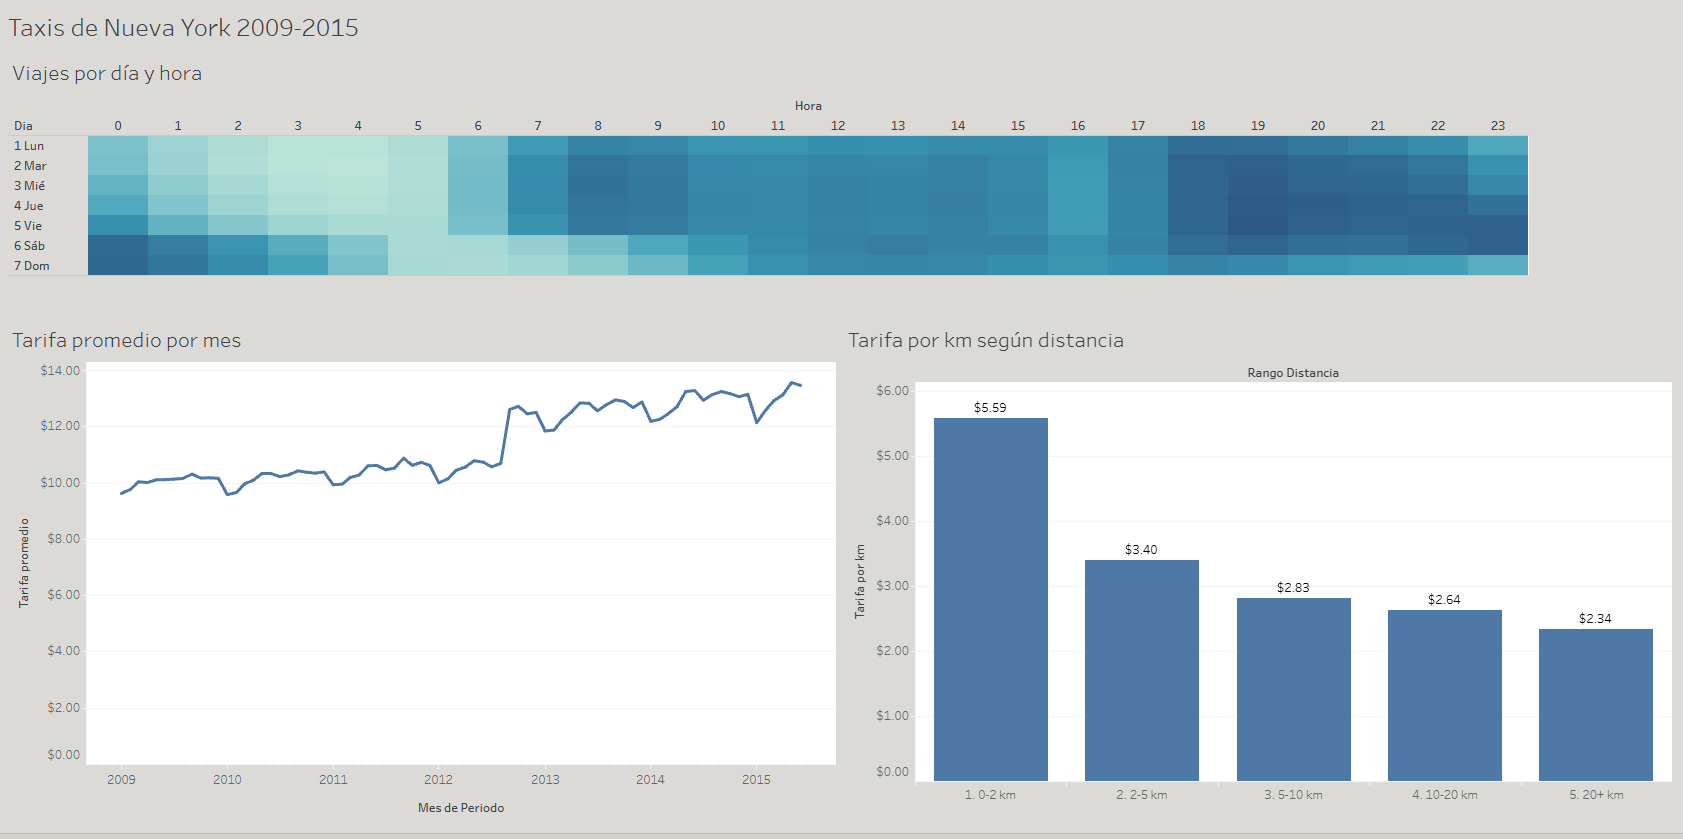

https://public.tableau.com/views/TaxisdeNuevaYork2009-2015/TaxisdeNuevaYork2009-2015

* Viajes por día y hora
Podemos ver que la mayor cantidad de viajes se concentra los días miércoles y jueves a altas horas de la noche, incluyendo también los sábados y domingos después de la medianoche.
* Tarifa promedio por mes
Podemos observar la evolución, donde es muy notorio el cambio mencionado en 2012 con un aumento de precio considerable.
* Tarifa por km según distancia
Podemos notar que el viaje corto tiene un costo de 5.59 USD por kilómetro, a gran contraste con los viajes largos de más de 20 km, que tienen un costo de 2.34 USD por kilómetro.

In [27]:
nombres_dias = F.array([F.lit(d) for d in ["7 Dom", "1 Lun", "2 Mar", "3 Mié", "4 Jue", "5 Vie", "6 Sáb"]])

tablero = (
    df_features
    .withColumn("periodo", F.make_date(F.col("anio"), F.col("mes"), F.lit(1)))
    .withColumn("dia", F.element_at(nombres_dias, F.col("dia_semana") + 1))
    .groupBy("periodo", "anio", "mes", "dia", "hora", "rango_distancia")
    .agg(
        F.count("*").alias("viajes"),
        F.round(F.sum("fare_amount"), 2).alias("suma_tarifa"),
        F.round(F.sum("distancia_km"), 2).alias("suma_km"),
    )
    .orderBy("periodo", "dia", "hora", "rango_distancia")
)

with cronometro("Agregar y exportar el CSV del tablero"):
    ruta_tablero = exportar_csv(tablero, "tablero_taxi.csv")

resumen_tablero = pd.read_csv(ruta_tablero)
print(f"Filas del CSV: {len(resumen_tablero):,}")
print(f"Viajes representados: {resumen_tablero['viajes'].sum():,}  (deben coincidir con las filas limpias: {df_features.count():,})")

if os.path.getsize(ruta_tablero) > 100 * 1024**2:
    print("AVISO: el CSV supera los 100 MB; quita alguna dimensión de la agrupación.")

resumen_tablero.head()

Guardado: /content/drive/MyDrive/IAconcentrada/PySparkTaxi/Outputs/tablero_taxi.csv  (3.59 MB)
[Agregar y exportar el CSV del tablero] 39.3 s
Filas del CSV: 65,515
Viajes representados: 54,053,708  (deben coincidir con las filas limpias: 54,053,708)


,periodo,anio,mes,dia,hora,rango_distancia,viajes,suma_tarifa,suma_km
0,2009-01-01,2009,1,1 Lun,0,1. 0-2 km,699,4413.31,777.49
1,2009-01-01,2009,1,1 Lun,0,2. 2-5 km,636,5714.85,2066.24
2,2009-01-01,2009,1,1 Lun,0,3. 5-10 km,359,5924.35,2500.29
3,2009-01-01,2009,1,1 Lun,0,4. 10-20 km,130,3788.35,1737.92
4,2009-01-01,2009,1,1 Lun,0,5. 20+ km,16,755.65,348.27


## Cerramos sesión

In [28]:
spark.stop()
print("Sesión de Spark cerrada.")

drive.flush_and_unmount()
print("Drive terminó de guardar los cambios y se desmontó.")

Sesión de Spark cerrada.
Drive terminó de guardar los cambios y se desmontó.
